# BFT65B Final Examination — A Big-Data Pipeline for Bank Failure Early Warning

## Overview & Reproducible Pipeline Architecture
This notebook implements an end-to-end, leak-free data engineering and machine learning pipeline designed for bank failure early warning (1-year ahead horizon) using four decades of US Federal Deposit Insurance Corporation (FDIC) Call Reports (`1984Q1–2026Q2`).

To ensure deterministic reproducibility, computational efficiency on a single workstation, and strict isolation against look-ahead bias, the workflow is organized as a **checkpoint-based directed acyclic pipeline**:
1. **Stage 1 — Acquisition & Canonical Storage (`data_raw/fdic/`):** Concurrent, resumable ingestion of all 170 quarterly `/financials` partitions alongside `/failures` and `/institutions`, enforced against a unified PyArrow schema (`CANONICAL_FIN_SCHEMA`) and benchmarked against raw CSV.
2. **Stage 2 — Data Quality & Point-in-Time Panel (`clean_panel.parquet`):** Automated quality diagnostics, within-bank historical forward-filling, strict reconciliation of bank exits (failures vs. mergers/voluntary closures), and construction of the point-in-time target label $y_{i,q} \in \{0, 1\}$.
3. **Stage 3 — Scalable Processing (`feature_table.parquet`):** Vectorized, lazy query execution in **Polars** benchmarked across three core transformation stages against **Pandas**, followed by distributed validation and Catalyst physical plan inspection in **PySpark**.
4. **Stage 4 — Leak-Free Feature Pipeline & Selection Audit:** CAMELS-aligned financial ratio engineering, automated future-corruption unit testing, Golden Out-of-Time partitioning (`<=2006Q4` vs. `>=2008Q1` with a 4-quarter embargo), heterogeneous `ColumnTransformer` preprocessing, and multi-stage feature selection auditing.
5. **Stage 5 — Modelling, Cached Tuning & Cost-Sensitive Validation (`models/`):** Atomic composite `Pipeline` encapsulation with `joblib.Memory` caching, purged expanding-window `GridSearchCV`, single-pass Out-of-Fold (OOF) cost-optimal threshold calibration, single-shot evaluation on the unseen holdout test set, production serialization, and distributed Spark MLlib verification.
6. **Stage 6 — Executive Synthesis:** Evidence-based answers to Q1–Q3, pipeline limitations, and architectural adaptation for the State Bank of Vietnam (SBV).

---
### Environment Setup & Checkpoint Execution Controls
Configuring deterministic random seeds (`RANDOM_SEED = 42`), standardized local directory paths, Windows-safe PySpark JVM guardrails (`127.0.0.1` loopback and clean local temp directory), hardware resource diagnostics, and execution flags (`SMOKE_TEST`, `FORCE_*`) so intermediate Parquet checkpoints are reused seamlessly across runs.

In [1]:
import os
import sys
import gc
import json
import time
import random
import shutil
import inspect
import logging
import warnings
import platform
import threading
import statistics
import psutil
from datetime import date
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

# -------------------------------------------------------------------------
# 0. Windows PySpark Anti-Hang Guardrails (MUST run before SparkSession)
# -------------------------------------------------------------------------
IS_WINDOWS = platform.system() == "Windows"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

if IS_WINDOWS:
    SPARK_LOCAL_DIR = Path("C:/spark_temp")
    SPARK_LOCAL_DIR.mkdir(parents=True, exist_ok=True)
    # Auto-register C:\hadoop if winutils.exe is installed
    hadoop_dir = Path("C:/hadoop")
    if (hadoop_dir / "bin" / "winutils.exe").exists():
        os.environ["HADOOP_HOME"] = str(hadoop_dir)
        os.environ["PATH"] = f"{hadoop_dir / 'bin'};" + os.environ.get("PATH", "")
else:
    SPARK_LOCAL_DIR = Path("/tmp/spark_temp")
    SPARK_LOCAL_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import pyarrow as pa
import polars as pl
import requests
import joblib
from joblib import Memory
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

# -------------------------------------------------------------------------
# 1. Pipeline Execution Flags & Deterministic Seeds
# -------------------------------------------------------------------------
SMOKE_TEST = False
FORCE_DOWNLOAD = False
FORCE_CLEAN = False
FORCE_FEATURES = False
RUN_OPTIONAL_RFECV = False

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# -------------------------------------------------------------------------
# 2. Standardized Local Directory Layout
# -------------------------------------------------------------------------
cwd = Path.cwd().resolve()
ROOT_DIR = cwd.parent if cwd.name == "notebooks" else Path(".")

RAW_DIR = ROOT_DIR / "data_raw" / "fdic"
PROC_DIR = ROOT_DIR / "data_processed"
MODEL_DIR = ROOT_DIR / "models"
RES_DIR = ROOT_DIR / "results"
FIG_DIR = RES_DIR / "figures"
CACHE_DIR = ROOT_DIR / "cache" / "sklearn"

for d in [RAW_DIR / "financials", PROC_DIR, MODEL_DIR, RES_DIR, FIG_DIR, CACHE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Environment   : Local Workstation ({platform.system()} {platform.release()})")
print(f"Python Binary : {sys.executable}")
print(f"Spark Temp Dir: {SPARK_LOCAL_DIR.as_posix()}")
print(f"CPU model     : {platform.processor()}")
print(f"CPU cores     : {psutil.cpu_count(logical=False)} physical / {psutil.cpu_count(logical=True)} logical")
print(f"RAM           : {round(psutil.virtual_memory().total / 1e9, 2)} GB")

Environment   : Local Workstation (Windows 10)
Python Binary : c:\Users\Admin\AppData\Local\Programs\Python\Python311\python.exe
Spark Temp Dir: C:/spark_temp
CPU model     : Intel64 Family 6 Model 126 Stepping 5, GenuineIntel
CPU cores     : 4 physical / 8 logical
RAM           : 8.35 GB


# Part 1: Data Acquisition, Canonical Schema & Storage Layout

### 1.1 Reproducible & Resumable API Ingestion
We extract three relational tables from the public FDIC BankFind API linked by the unique certificate identifier (`CERT`):
* **`/financials` (`1984Q1–2026Q2`, 170 quarters):** Restricted to 33 dense balance-sheet, income-statement, asset-quality, and regulatory capital fields mapped to the **CAMELS** supervisory framework. Downloads run concurrently via a thread-safe worker pool with exponential back-off and an atomic JSON manifest (`manifest_financials.json`) to allow instant resumption without duplicating quarters.
* **`/failures` & `/institutions`:** Full historical failure resolutions and institutional metadata tables downloaded and verified against API meta row counts.

### 1.2 Partitioned Parquet Layout & Canonical Schema Enforcement
Quarterly financial snapshots are stored in a Hive-style partitioned layout (`REPDTE=YYYYMMDD/data.parquet`) compressed with **Snappy**. Because API columns with intermittent nulls can infer as `Int64` in some quarters and `Float64` in others, we enforce an explicit PyArrow `CANONICAL_FIN_SCHEMA` across all 170 partitions to prevent cross-partition schema drift. Finally, we benchmark write speed, full scan speed, filtered range queries (`2008–2012` partition pruning), and disk footprint against a raw CSV baseline.

In [2]:
print("=== PART 1: DATA ACQUISITION, SCHEMA UNIFICATION & STORAGE BENCHMARK ===")
import pyarrow.parquet as pq

BASE_URL = "https://api.fdic.gov/banks"
PAGE_SIZE = 10_000
START_DATE = "1984-03-31"
END_DATE = "2026-06-30"

FIN_FIELDS = [
    "CERT", "REPDTE", "STNAME",
    "ASSET", "DEP", "DEPDOM", "EQ", "BRO", "CHBAL", "SC",
    "LNLSGR", "LNLSNET", "LNRE", "LNCI", "LNCON", "LNATRES",
    "NCLNLS", "P3ASSET", "P9ASSET", "NAASSET", "NTLNLS", "ORE",
    "NETINC", "INTINC", "EINTEXP", "NONII", "NONIX", "ELNATR",
    "ROA", "ROE", "NIMY",
    "RBC1AAJ", "RBCRWAJ",
]
FAIL_FIELDS = ["CERT", "NAME", "CITYST", "FAILDATE", "FAILYR", "COST", "QBFASSET", "QBFDEP", "RESTYPE"]
INST_FIELDS = ["CERT", "NAME", "STNAME", "BKCLASS", "ACTIVE", "ESTYMD", "ENDEFYMD", "CHANGEC1", "INSDATE"]

# Explicit Canonical PyArrow Schema across all 170 quarterly partitions
CANONICAL_FIN_SCHEMA = pa.schema(
    [("CERT", pa.int64()), ("REPDTE", pa.int64()), ("STNAME", pa.string())] +
    [(col, pa.float64()) for col in FIN_FIELDS[3:]]
)

def to_canonical_arrow_table(df: pd.DataFrame) -> pa.Table:
    out = pd.DataFrame(index=df.index)
    out["CERT"] = pd.to_numeric(df["CERT"], errors="coerce").astype("int64")
    out["REPDTE"] = pd.to_numeric(df["REPDTE"], errors="coerce").astype("int64")
    out["STNAME"] = df["STNAME"].where(df["STNAME"].notna(), None).astype("object")
    for col in FIN_FIELDS[3:]:
        out[col] = pd.to_numeric(df[col], errors="coerce").astype("float64") if col in df.columns else np.nan
    return pa.Table.from_pandas(out, schema=CANONICAL_FIN_SCHEMA, preserve_index=False)

def unify_partition_schemas(raw_dir: Path) -> None:
    files = sorted((raw_dir / "financials").glob("REPDTE=*/data.parquet"))
    fixed_cnt = 0
    for f in files:
        if not pq.read_schema(f).equals(CANONICAL_FIN_SCHEMA, check_metadata=False):
            tbl = to_canonical_arrow_table(pd.read_parquet(f))
            tmp_f = f.with_suffix(".schema.tmp.parquet")
            pq.write_table(tbl, tmp_f, compression="snappy")
            tmp_f.replace(f)
            fixed_cnt += 1
    print(f"[Schema Check] Audited {len(files)} partitions -> Unified {fixed_cnt} mismatched partitions to CANONICAL_FIN_SCHEMA.")

_thread_local = threading.local()
_manifest_lock = threading.Lock()

def get_session() -> requests.Session:
    if not hasattr(_thread_local, "session"):
        s = requests.Session()
        s.headers.update({"User-Agent": "BFT65B-FDIC-Pipeline/2.0"})
        _thread_local.session = s
    return _thread_local.session

def get_json(endpoint: str, params: dict, max_retries: int = 6, pause: float = 0.15) -> dict:
    url = f"{BASE_URL}/{endpoint}"
    sess = get_session()
    for attempt in range(1, max_retries + 1):
        try:
            r = sess.get(url, params=params, timeout=180)
            if r.status_code == 200:
                time.sleep(pause)
                return r.json()
            if r.status_code == 429 or r.status_code >= 500:
                time.sleep(min(60, 2 ** attempt))
                continue
        except requests.RequestException:
            time.sleep(min(60, 2 ** attempt))
    raise RuntimeError(f"Failed request to {url} after {max_retries} retries.")

def fetch_all(endpoint: str, fields: list[str], filters: str | None = None, sort_by: str = "CERT") -> tuple[pd.DataFrame, int]:
    rows, offset, total = [], 0, None
    while True:
        params = {
            "fields": ",".join(fields),
            "limit": PAGE_SIZE,
            "offset": offset,
            "sort_by": sort_by,
            "sort_order": "ASC",
            "format": "json",
        }
        if filters:
            params["filters"] = filters
        js = get_json(endpoint, params)
        total = js["meta"]["total"]
        page = [rec["data"] for rec in js["data"]]
        rows.extend(page)
        offset += len(page)
        if not page or offset >= total:
            break
    df = pd.DataFrame(rows).drop(columns=["ID"], errors="ignore")
    return df, total

def quarter_ends(start: date, end: date) -> list[str]:
    ends = []
    for y in range(start.year, end.year + 1):
        for m, d in ((3, 31), (6, 30), (9, 30), (12, 31)):
            q = date(y, m, d)
            if start <= q <= end:
                ends.append(q.strftime("%Y%m%d"))
    return ends

def download_all_fdic_tables(raw_dir: Path, quarters: list[str], force: bool = False, max_workers: int = 3) -> None:
    fin_dir = raw_dir / "financials"
    manifest_path = raw_dir / "manifest_financials.json"
    manifest = json.loads(manifest_path.read_text()) if (manifest_path.exists() and not force) else {}

    # 1. Download Failures & Institutions tables
    for endpoint, fields, fname in [
        ("failures", FAIL_FIELDS, "failures.parquet"),
        ("institutions", INST_FIELDS, "institutions.parquet"),
    ]:
        fpath = raw_dir / fname
        if fpath.exists() and not force:
            print(f"[SKIP] {fname} already exists ({len(pd.read_parquet(fpath)):,} rows).")
            continue
        t0 = time.time()
        df_tbl, api_total = fetch_all(endpoint, fields)
        assert len(df_tbl) == api_total, f"Incomplete {endpoint}: {len(df_tbl)} != {api_total}"
        tmp_path = fpath.with_suffix(".tmp.parquet")
        df_tbl.to_parquet(tmp_path, index=False, engine="pyarrow", compression="snappy")
        tmp_path.replace(fpath)
        print(f"[OK] Downloaded {fname}: {len(df_tbl):,} rows in {time.time() - t0:.1f}s")

    # 2. Concurrent Resumable Download for Quarterly Financials
    pending = [
        q for q in quarters
        if force or not ((fin_dir / f"REPDTE={q}" / "data.parquet").exists() and manifest.get(q, {}).get("complete"))
    ]
    if not pending:
        print(f"[SKIP] All {len(quarters)} quarterly financial partitions are already complete.")
        return

    print(f"Downloading {len(pending)} pending quarters with {max_workers} concurrent workers...")
    def _worker(q: str):
        part_dir = fin_dir / f"REPDTE={q}"
        part_dir.mkdir(parents=True, exist_ok=True)
        target = part_dir / "data.parquet"
        tmp_target = part_dir / "data.tmp.parquet"

        df_q, total_q = fetch_all("financials", FIN_FIELDS, filters=f"REPDTE:{q}")
        if df_q.empty:
            return
        tbl_q = to_canonical_arrow_table(df_q)
        pq.write_table(tbl_q, tmp_target, compression="snappy")
        tmp_target.replace(target)

        is_complete = (len(df_q) == total_q) and (not df_q.duplicated(["CERT", "REPDTE"]).any())
        with _manifest_lock:
            manifest[q] = {"rows": len(df_q), "api_total": total_q, "complete": bool(is_complete)}
            manifest_path.write_text(json.dumps(manifest, indent=1))

    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        list(pool.map(_worker, pending))

def verify_completeness(raw_dir: Path, expected_quarters: list[str]) -> bool:
    manifest = json.loads((raw_dir / "manifest_financials.json").read_text())
    fin_scan = pl.scan_parquet(str(raw_dir / "financials" / "REPDTE=*" / "data.parquet"))
    stats = fin_scan.select([
        pl.len().alias("total_rows"),
        pl.col("CERT").n_unique().alias("unique_certs"),
        pl.col("REPDTE").n_unique().alias("unique_quarters"),
    ]).collect().to_dicts()[0]

    dup_count = (
        fin_scan.group_by(["CERT", "REPDTE"]).len()
        .filter(pl.col("len") > 1)
        .select(pl.len())
        .collect().item()
    )
    incomplete_q = [q for q in expected_quarters if not manifest.get(q, {}).get("complete", False)]
    df_fail = pd.read_parquet(raw_dir / "failures.parquet")
    df_inst = pd.read_parquet(raw_dir / "institutions.parquet")

    print("\n=== COMPLETENESS AUDIT (ALL 3 FDIC TABLES) ===")
    print(f"Expected Quarters (1984Q1-2026Q2) : {len(expected_quarters)}")
    print(f"Downloaded Quarters in Parquet    : {stats['unique_quarters']}")
    print(f"Total Financials Panel Rows       : {stats['total_rows']:,}")
    print(f"Distinct Banks (CERT) in Panel    : {stats['unique_certs']:,}")
    print(f"Duplicate (CERT, REPDTE) Keys     : {dup_count}")
    print(f"Incomplete Quarters               : {incomplete_q if incomplete_q else 'None'}")
    print(f"Failures Table Rows (Unique CERT) : {len(df_fail):,} ({df_fail['CERT'].nunique():,})")
    print(f"Institutions Table Rows           : {len(df_inst):,}")
    return (dup_count == 0) and (len(incomplete_q) == 0)

all_quarters = quarter_ends(date.fromisoformat(START_DATE), date.fromisoformat(END_DATE))
if SMOKE_TEST:
    all_quarters = all_quarters[-8:]

download_all_fdic_tables(RAW_DIR, all_quarters, force=FORCE_DOWNLOAD, max_workers=3)
unify_partition_schemas(RAW_DIR)
ok_complete = verify_completeness(RAW_DIR, all_quarters)
assert ok_complete, "Data acquisition incomplete!"

# -------------------------------------------------------------------------
# 3. Fair Storage Benchmark: Partitioned Parquet (Snappy) vs. Raw CSV
# -------------------------------------------------------------------------
bench_csv_path = RES_DIR / "benchmark_storage.csv"
if not bench_csv_path.exists() or FORCE_DOWNLOAD:
    temp_bench = ROOT_DIR / "temp_storage_bench"
    temp_bench.mkdir(exist_ok=True)
    csv_file = temp_bench / "full_panel.csv"
    pq_dir = temp_bench / "panel_partitioned"

    base_df = pl.scan_parquet(str(RAW_DIR / "financials" / "REPDTE=*" / "data.parquet")).collect().to_pandas()

    def _med_time(fn, *args, runs=3, setup=None, **kwargs):
        ts = []
        for i in range(runs + 1):
            if setup:
                setup()
            t0 = time.time()
            out = fn(*args, **kwargs)
            if i > 0:
                ts.append(time.time() - t0)
        return statistics.median(ts), out

    csv_w, _ = _med_time(base_df.to_csv, csv_file, index=False)
    pq_w, _ = _med_time(
        base_df.to_parquet, pq_dir, partition_cols=["REPDTE"], engine="pyarrow", compression="snappy",
        setup=lambda: shutil.rmtree(pq_dir, ignore_errors=True)
    )
    csv_r_full, _ = _med_time(pd.read_csv, csv_file, low_memory=False)
    pq_r_full, _ = _med_time(pd.read_parquet, pq_dir, engine="pyarrow")

    csv_r_filt, _ = _med_time(lambda: pd.read_csv(csv_file, low_memory=False).query("20080101 <= REPDTE <= 20121231"))
    pq_r_filt, _ = _med_time(lambda: pd.read_parquet(pq_dir, engine="pyarrow", filters=[("REPDTE", ">=", 20080101), ("REPDTE", "<=", 20121231)]))

    csv_mb = os.path.getsize(csv_file) / (1024 ** 2)
    pq_mb = sum(f.stat().st_size for f in pq_dir.rglob("*") if f.is_file()) / (1024 ** 2)

    bench_storage_df = pd.DataFrame([
        {"Metric": "Disk Footprint (MB)", "Raw_CSV": round(csv_mb, 2), "Partitioned_Parquet": round(pq_mb, 2), "Speedup_or_Compression": f"{csv_mb/pq_mb:.2f}x smaller"},
        {"Metric": "Write Full Panel (s)", "Raw_CSV": round(csv_w, 2), "Partitioned_Parquet": round(pq_w, 2), "Speedup_or_Compression": f"{csv_w/pq_w:.2f}x faster"},
        {"Metric": "Read Full Panel (s)", "Raw_CSV": round(csv_r_full, 2), "Partitioned_Parquet": round(pq_r_full, 2), "Speedup_or_Compression": f"{csv_r_full/pq_r_full:.2f}x faster"},
        {"Metric": "Filtered Read 2008-2012 (s)", "Raw_CSV": round(csv_r_filt, 2), "Partitioned_Parquet": round(pq_r_filt, 2), "Speedup_or_Compression": f"{csv_r_filt/pq_r_filt:.2f}x faster"},
    ])
    bench_storage_df.to_csv(bench_csv_path, index=False)
    shutil.rmtree(temp_bench, ignore_errors=True)
    del base_df
    gc.collect()

print("\n=== STORAGE BENCHMARK (MEDIAN OF 3 RUNS) ===")
print(pd.read_csv(bench_csv_path).to_string(index=False))

=== PART 1: DATA ACQUISITION, SCHEMA UNIFICATION & STORAGE BENCHMARK ===
[SKIP] failures.parquet already exists (4,117 rows).
[SKIP] institutions.parquet already exists (27,838 rows).
[SKIP] All 170 quarterly financial partitions are already complete.
[Schema Check] Audited 170 partitions -> Unified 0 mismatched partitions to CANONICAL_FIN_SCHEMA.

=== COMPLETENESS AUDIT (ALL 3 FDIC TABLES) ===
Expected Quarters (1984Q1-2026Q2) : 170
Downloaded Quarters in Parquet    : 170
Total Financials Panel Rows       : 1,682,739
Distinct Banks (CERT) in Panel    : 24,064
Duplicate (CERT, REPDTE) Keys     : 0
Incomplete Quarters               : None
Failures Table Rows (Unique CERT) : 4,117 (3,585)
Institutions Table Rows           : 27,838

=== STORAGE BENCHMARK (MEDIAN OF 3 RUNS) ===
                     Metric  Raw_CSV  Partitioned_Parquet Speedup_or_Compression
        Disk Footprint (MB)   424.12               244.48          1.73x smaller
       Write Full Panel (s)    36.84                 

# Part 2: Automated Data Quality Audit & Point-in-Time Panel Construction

### 2.1 Systematic Quality Diagnostics & Look-Ahead-Safe Mitigation
Before constructing analytical features, the raw panel undergoes an automated diagnostic audit across four dimensions:
1. **Structural Missingness & Regime Shifts:** Quantifying missing rates overall and contrasting pre-2000 vs. post-2000 reporting regimes (e.g., `P3ASSET` and risk-based capital fields introduced under Basel I).
2. **Logical & Domain Violations:** Filtering records with missing `CERT`, non-positive total assets (`ASSET <= 0`), or negative deposits (`DEP < 0`).
3. **Point-in-Time Imputation:** Core profitability and capital ratios (`ROA`, `ROE`, `NIMY`, `RBC1AAJ`, `RBCRWAJ`) are forward-filled (`ffill`) strictly within each bank's chronological history (`groupby('CERT')`). Backward-filling is strictly prohibited to eliminate look-ahead bias. Extreme reporting outliers (e.g., `|ROA| > 100%`) are preserved here and capped exclusively using training-set quantiles inside Part 4.
4. **Right-Censoring Cutoff (`2025Q2`):** Although raw data are acquired through `2026Q2`, the modelling panel is truncated at `2025-06-30` so that every bank-quarter observation has a complete, uncensored 4-quarter forward window to observe potential failure.

### 2.2 Exit Reconciliation & Target Label Definition
Using `institutions.parquet` (`ACTIVE == 0`) alongside `failures.parquet`, we explicitly separate **true regulatory failures** from **non-failure exits** (mergers, consolidations, and voluntary liquidations, which are retained as healthy observations $y_{i,q} = 0$ up to their final filing). The binary early-warning target is defined strictly point-in-time:
$$y_{i,q} = \mathbb{I}\Big(\text{FAILDATE}_i \in (q,\; q + 4\text{ quarters}]\Big)$$

In [3]:
print("=== PART 2: AUTOMATED DATA QUALITY REPORT & POINT-IN-TIME PANEL ===")

clean_panel_path = PROC_DIR / "clean_panel.parquet"
part2_report_path = RES_DIR / "part2_audit_report.txt"

if clean_panel_path.exists() and part2_report_path.exists() and not FORCE_CLEAN:
    print(f"[SKIP] Loading cached clean panel & audit report from: {clean_panel_path}\n")
    print(part2_report_path.read_text(encoding="utf-8"))
else:
    t0 = time.time()
    lines = []
    def log(msg: str = ""):
        print(msg)
        lines.append(msg)

    # Read full raw panel via Polars for speed & low memory
    raw_lf = pl.scan_parquet(str(RAW_DIR / "financials" / "REPDTE=*" / "data.parquet"))
    df_fin = raw_lf.collect().to_pandas()

    # Standardize CERT and REPDTE immediately across all 3 tables
    df_fin["CERT"] = pd.to_numeric(df_fin["CERT"], errors="coerce").astype("Int64")
    df_fin["REPDTE"] = pd.to_datetime(df_fin["REPDTE"].astype(str), format="%Y%m%d")

    df_fail = pd.read_parquet(RAW_DIR / "failures.parquet")
    df_fail["CERT"] = pd.to_numeric(df_fail["CERT"], errors="coerce").astype("Int64")
    df_fail["FAILDATE"] = pd.to_datetime(df_fail["FAILDATE"], errors="coerce")

    df_inst = pd.read_parquet(RAW_DIR / "institutions.parquet")
    df_inst["CERT"] = pd.to_numeric(df_inst["CERT"], errors="coerce").astype("Int64")
    df_inst["ACTIVE_NUM"] = pd.to_numeric(df_inst["ACTIVE"], errors="coerce")
    df_inst["ENDEFYMD_DT"] = pd.to_datetime(df_inst["ENDEFYMD"], errors="coerce")

    # ---------------------------------------------------------------------
    # SECTION 1: RAW DATASET COVERAGE & INDUSTRY CONSOLIDATION OVERVIEW
    # ---------------------------------------------------------------------
    n_init = len(df_fin)
    q_counts = df_fin.groupby("REPDTE")["CERT"].nunique()
    log("1. RAW CALL REPORT PANEL OVERVIEW (1984Q1 - 2026Q2):")
    log(f"   - Total raw bank-quarter observations : {n_init:,}")
    log(f"   - Distinct institutions (unique CERT) : {df_fin['CERT'].nunique():,}")
    log(f"   - Reporting quarters covered          : {df_fin['REPDTE'].nunique()} quarters ({df_fin['REPDTE'].min():%Y-%m-%d} -> {df_fin['REPDTE'].max():%Y-%m-%d})")
    log(f"   - Active filers per quarter           : {q_counts.iloc[0]:,} (1984Q1) -> {q_counts.iloc[-1]:,} (2026Q2) [Mean: {q_counts.mean():,.0f}/quarter]")

    # ---------------------------------------------------------------------
    # SECTION 2: MISSING VALUES & STRUCTURAL REGIME SHIFT AUDIT
    # ---------------------------------------------------------------------
    missing_cnt = df_fin.isnull().sum()
    missing_pct = (missing_cnt / n_init) * 100
    pre2000_mask = df_fin["REPDTE"] < "2000-01-01"
    miss_pre2000 = df_fin.loc[pre2000_mask].isnull().mean() * 100
    miss_post2000 = df_fin.loc[~pre2000_mask].isnull().mean() * 100

    mitigation_map = {
        "ROA": "Within-bank historical ffill -> drop persistent nulls",
        "ROE": "Within-bank historical ffill -> drop persistent nulls",
        "NIMY": "Within-bank historical ffill -> train-only median imputer",
        "RBC1AAJ": "Within-bank ffill + MissingIndicator (Basel I regime)",
        "RBCRWAJ": "Within-bank ffill + MissingIndicator (Basel I regime)",
        "P3ASSET": "Preserved + MissingIndicator + train-only median imputer",
    }

    dq_df = pd.DataFrame({
        "Missing_Rows": missing_cnt,
        "Missing_Pct": missing_pct.round(3),
        "Pre2000_Pct": miss_pre2000.round(2),
        "Post2000_Pct": miss_post2000.round(2),
    })
    dq_df = dq_df[dq_df["Missing_Rows"] > 0].sort_values("Missing_Pct", ascending=False)
    dq_df["Mitigation_Rule"] = [
        mitigation_map.get(col, "Preserved + MissingIndicator + train-only median imputer")
        for col in dq_df.index
    ]
    dq_df.to_csv(RES_DIR / "data_quality.csv")

    log("\n2. MISSING VALUES & REGULATORY REGIME SHIFT AUDIT (ALL AFFECTED FIELDS):")
    log(dq_df.to_string())

    # ---------------------------------------------------------------------
    # SECTION 3: ACCOUNTING IDENTITIES, LOGICAL CHECKS & OUTLIER QUANTILES
    # ---------------------------------------------------------------------
    invalid_cert = int(df_fin["CERT"].isna().sum())
    dup_keys = int(df_fin.duplicated(["CERT", "REPDTE"]).sum())
    neg_asset = int((df_fin["ASSET"] <= 0).sum())
    neg_dep = int((df_fin["DEP"] < 0).sum())
    depdom_gt_dep = int(((df_fin["DEPDOM"].notna()) & (df_fin["DEP"].notna()) & (df_fin["DEPDOM"] > df_fin["DEP"] + 1)).sum())
    lnnet_gt_lngr = int(((df_fin["LNLSNET"].notna()) & (df_fin["LNLSGR"].notna()) & (df_fin["LNLSNET"] > df_fin["LNLSGR"] + 1)).sum())
    extreme_roa = int(((df_fin["ROA"] > 100) | (df_fin["ROA"] < -100)).sum())
    extreme_roe = int(((df_fin["ROE"] > 500) | (df_fin["ROE"] < -500)).sum())

    log("\n3. INTEGRITY, ACCOUNTING CONSISTENCY & EXTREME OUTLIER DIAGNOSTICS:")
    log(f"   - Invalid / Null CERT rows            : {invalid_cert:,}")
    log(f"   - Duplicate (CERT, REPDTE) keys       : {dup_keys:,}")
    log(f"   - Non-positive Total Assets (ASSET<=0): {neg_asset:,}")
    log(f"   - Negative Total Deposits (DEP < 0)   : {neg_dep:,}")
    log(f"   - Domestic > Total Deposits (DEPDOM)  : {depdom_gt_dep:,}")
    log(f"   - Net Loans > Gross Loans (LNLSNET)   : {lnnet_gt_lngr:,}")
    log(f"   - Extreme ROA (|ROA| > 100%)          : {extreme_roa:,} rows (retained for Train-Only Winsorizer)")
    log(f"   - Extreme ROE (|ROE| > 500%)          : {extreme_roe:,} rows (retained for Train-Only Winsorizer)")

    # Quantile profile justifying TrainOnlyWinsorizer in Part 4
    outlier_check_cols = ["ROA", "ROE", "NIMY", "ASSET", "NCLNLS"]
    q_summary = []
    for c in outlier_check_cols:
        s = df_fin[c].dropna()
        q_summary.append({
            "Field": c,
            "Min": round(float(s.min()), 2),
            "P0.1": round(float(s.quantile(0.001)), 2),
            "Median": round(float(s.median()), 2),
            "P99.9": round(float(s.quantile(0.999)), 2),
            "Max": round(float(s.max()), 2),
        })
    log("\n   Tail Distribution Quantiles (Justifying 1st/99th Train-Only Winsorization):")
    log(pd.DataFrame(q_summary).to_string(index=False))

    # ---------------------------------------------------------------------
    # SECTION 4: POINT-IN-TIME CLEANING & ROW ATTRITION WATERFALL
    # ---------------------------------------------------------------------
    df_valid = df_fin[
        df_fin["CERT"].notna() & (df_fin["ASSET"] > 0) & (df_fin["DEP"] >= 0)
    ].sort_values(["CERT", "REPDTE"]).reset_index(drop=True)
    n_after_domain = len(df_valid)

    # Forward-fill core profitability & capital ratios strictly within each bank's past history
    ratio_cols = ["ROA", "ROE", "NIMY", "RBC1AAJ", "RBCRWAJ"]
    nulls_before_ffill = df_valid[ratio_cols].isnull().sum()
    df_valid[ratio_cols] = df_valid.groupby("CERT")[ratio_cols].ffill()
    nulls_after_ffill = df_valid[ratio_cols].isnull().sum()
    filled_counts = (nulls_before_ffill - nulls_after_ffill).to_dict()

    df_clean = df_valid.dropna(subset=["ROA", "ROE"]).reset_index(drop=True)
    n_after_ratio_drop = len(df_clean)

    # Restrict Modelling Scope to <= 2025Q2 (full 4-quarter forward window observable)
    cutoff_date = pd.to_datetime("2025-06-30")
    df_panel = df_clean[df_clean["REPDTE"] <= cutoff_date].copy()
    n_final_panel = len(df_panel)

    log("\n4. POINT-IN-TIME CLEANING & ROW ATTRITION WATERFALL:")
    log(f"   - Step 0: Raw downloaded panel (1984Q1-2026Q2)        : {n_init:>10,} rows")
    log(f"   - Step 1: Filter invalid CERT / ASSET<=0 / DEP<0      : {n_after_domain:>10,} rows (-{n_init - n_after_domain:,})")
    log(f"   - Step 2: Within-bank historical ffill (cells filled) : {filled_counts}")
    log(f"   - Step 3: Drop persistent missing ROA/ROE             : {n_after_ratio_drop:>10,} rows (-{n_after_domain - n_after_ratio_drop:,})")
    log(f"   - Step 4: Right-censoring cutoff (REPDTE <= 2025Q2)   : {n_final_panel:>10,} rows (-{n_after_ratio_drop - n_final_panel:,} censored quarters)")

    # ---------------------------------------------------------------------
    # SECTION 5: EXITED BANKS & FAILURE RECONCILIATION AUDIT
    # ---------------------------------------------------------------------
    df_fail_valid = df_fail[df_fail["CERT"].notna() & df_fail["FAILDATE"].notna()].copy()
    df_fail_unique = df_fail_valid.sort_values("FAILDATE").drop_duplicates("CERT", keep="first")

    df_panel = df_panel.merge(df_fail_unique[["CERT", "FAILDATE"]], on="CERT", how="left")
    assert df_panel.duplicated(["CERT", "REPDTE"]).sum() == 0, "Merge created duplicate keys!"

    # Construct Point-in-Time Label: y_{i,q} = 1{fail in (q, q + 4 quarters]}
    target_horizon = df_panel["REPDTE"] + pd.DateOffset(years=1)
    df_panel["LABEL_FAIL_1YR"] = np.where(
        (df_panel["FAILDATE"] > df_panel["REPDTE"]) & (df_panel["FAILDATE"] <= target_horizon),
        1, 0
    ).astype(np.int8)

    panel_certs = set(df_panel["CERT"].unique())
    inst_in_panel = df_inst[df_inst["CERT"].isin(panel_certs)].copy()
    inactive_certs = set(inst_in_panel.loc[inst_in_panel["ACTIVE_NUM"] == 0, "CERT"])
    all_fail_certs = set(df_fail_unique["CERT"])
    failed_certs_in_panel = panel_certs & all_fail_certs
    other_exit_certs = inactive_certs - all_fail_certs
    captured_fail_certs = set(df_panel.loc[df_panel["LABEL_FAIL_1YR"] == 1, "CERT"])
    uncaptured_fail_certs = failed_certs_in_panel - captured_fail_certs

    # Diagnose why uncaptured failed banks in panel have 0 positive labels
    uncap_diag = df_panel[df_panel["CERT"].isin(uncaptured_fail_certs)].groupby("CERT").agg(
        last_rep=("REPDTE", "max"),
        fail_dt=("FAILDATE", "first")
    )
    n_failed_before_first_rep = int((uncap_diag["fail_dt"] <= uncap_diag["last_rep"]).sum())
    n_stale_last_filing = int(((uncap_diag["fail_dt"] > uncap_diag["last_rep"]) & (uncap_diag["fail_dt"] > uncap_diag["last_rep"] + pd.DateOffset(years=1))).sum())

    # Top CHANGEC1 codes among non-failure exits (mergers, absorptions, voluntary closures)
    non_fail_exits_df = inst_in_panel[inst_in_panel["CERT"].isin(other_exit_certs)]
    top_changec1 = non_fail_exits_df["CHANGEC1"].fillna("MISSING").astype(str).value_counts().head(5).to_dict()

    log("\n5. EXITED BANKS & FAILURE RECONCILIATION AUDIT (1984Q1 - 2025Q2):")
    log(f"   - Total unique failed banks in FDIC Failures table     : {len(all_fail_certs):,}")
    log(f"     * Failures outside panel scope (pre-1984 / non-filers): {len(all_fail_certs - panel_certs):,}")
    log(f"     * Failed banks present in modelling panel            : {len(failed_certs_in_panel):,}")
    log(f"       -> Contributing >= 1 positive label (y=1)          : {len(captured_fail_certs):,}")
    log(f"       -> Failed > 4Q after final Call Report (stale/gap) : {n_stale_last_filing:,}")
    log(f"       -> Failed on/before first observed filing          : {n_failed_before_first_rep:,}")
    log(f"   - Distinct banks in modelling panel                    : {len(panel_certs):,}")
    log(f"     * Active institutions (ACTIVE = 1)                   : {len(panel_certs - inactive_certs):,}")
    log(f"     * Inactive institutions (ACTIVE = 0)                 : {len(inactive_certs):,}")
    log(f"       -> True regulatory failures (in Failures table)    : {len(failed_certs_in_panel):,}")
    log(f"       -> Non-failure exits (mergers/acquisitions/etc.)   : {len(other_exit_certs):,} (treated as y=0)")
    log(f"       -> Top FDIC CHANGEC1 codes for non-failure exits   : {top_changec1}")

    # ---------------------------------------------------------------------
    # SECTION 6: TARGET LABEL DISTRIBUTION & HISTORICAL CRISIS CLUSTERING
    # ---------------------------------------------------------------------
    pos_rows = int(df_panel["LABEL_FAIL_1YR"].sum())
    avg_q_per_fail = pos_rows / max(len(captured_fail_certs), 1)

    regime_bins = [
        ("1984Q1 - 1993Q4 (S&L & Banking Crisis)", "1984-01-01", "1993-12-31"),
        ("1994Q1 - 2006Q4 (Great Moderation / Calm)", "1994-01-01", "2006-12-31"),
        ("2007Q1 - 2007Q4 (4-Quarter Embargo Gap)", "2007-01-01", "2007-12-31"),
        ("2008Q1 - 2014Q4 (Global Financial Crisis)", "2008-01-01", "2014-12-31"),
        ("2015Q1 - 2025Q2 (Post-GFC & 2023 Failures)", "2015-01-01", "2025-06-30"),
    ]
    regime_stats = []
    for label_era, d_start, d_end in regime_bins:
        sub = df_panel[(df_panel["REPDTE"] >= d_start) & (df_panel["REPDTE"] <= d_end)]
        p_cnt = int(sub["LABEL_FAIL_1YR"].sum())
        u_certs = int(sub.loc[sub["LABEL_FAIL_1YR"] == 1, "CERT"].nunique())
        regime_stats.append({
            "Historical_Regime": label_era,
            "Bank_Quarters": f"{len(sub):,}",
            "Pos_Labels (y=1)": f"{p_cnt:,}",
            "Unique_Failing_CERTs": f"{u_certs:,}",
            "Pos_Rate": f"{(p_cnt / max(len(sub), 1)) * 100:.3f}%"
        })

    log("\n6. POINT-IN-TIME TARGET LABEL (LABEL_FAIL_1YR) & CRISIS CLUSTERING:")
    log(f"   - Total Panel Observations : {n_final_panel:,} (y=0: {n_final_panel - pos_rows:,} | y=1: {pos_rows:,})")
    log(f"   - Overall Failure Rate     : {(pos_rows / n_final_panel) * 100:.3f}% (Avg {avg_q_per_fail:.2f} positive quarters per captured failure)")
    log("\n" + pd.DataFrame(regime_stats).to_string(index=False))

    df_panel.drop(columns=["FAILDATE"], inplace=True)
    df_panel["REPDTE"] = df_panel["REPDTE"].astype("datetime64[us]")
    df_panel.to_parquet(clean_panel_path, index=False, engine="pyarrow", compression="snappy")

    log(f"\n[SAVED] Spark-compatible clean_panel.parquet ({os.path.getsize(clean_panel_path)/(1024**2):.2f} MB) built in {time.time() - t0:.1f}s")
    part2_report_path.write_text("\n".join(lines), encoding="utf-8")

    del df_fin, df_valid, df_clean, df_panel
    gc.collect()

=== PART 2: AUTOMATED DATA QUALITY REPORT & POINT-IN-TIME PANEL ===
[SKIP] Loading cached clean panel & audit report from: data_processed\clean_panel.parquet

1. RAW CALL REPORT PANEL OVERVIEW (1984Q1 - 2026Q2):
   - Total raw bank-quarter observations : 1,682,739
   - Distinct institutions (unique CERT) : 24,064
   - Reporting quarters covered          : 170 quarters (1984-03-31 -> 2026-06-30)
   - Active filers per quarter           : 17,930 (1984Q1) -> 4,314 (2026Q2) [Mean: 9,898/quarter]

2. MISSING VALUES & REGULATORY REGIME SHIFT AUDIT (ALL AFFECTED FIELDS):
         Missing_Rows  Missing_Pct  Pre2000_Pct  Post2000_Pct                                           Mitigation_Rule
P3ASSET        972047       57.766       100.00          5.41  Preserved + MissingIndicator + train-only median imputer
NTLNLS          79929        4.750         8.38          0.25  Preserved + MissingIndicator + train-only median imputer
NAASSET         77749        4.620         8.35          0.00  Preser

# Part 3: Scalable Processing (Polars LazyFrame vs. Pandas & PySpark)

### 3.1 Polars Query Engine & Multi-Stage Transformation Benchmark
To process 42+ years of bank Call Reports efficiently on a single workstation, we implement the core data transformations using **Polars `LazyFrame`**. Unlike eager row-oriented execution in Pandas, Polars builds a logical query plan and applies **predicate pushdown** (filtering rows at scan time), **projection pushdown** (reading only required Parquet columns), and **SIMD-vectorized multi-threaded execution** across `CERT`-partitioned window expressions.

We conduct a fair median-of-3 benchmark (after warm-up) comparing **Pandas** and **Polars** across three representative workloads on the full `1984Q1–2026Q2` panel:
1. **Stage 1 — Scan, Filter & Clean:** Predicate filtering across all 170 Parquet partitions.
2. **Stage 2 — Panel Window Transformations:** Sorting by `(CERT, REPDTE)` and computing grouped lags, first differences, and 4-quarter rolling volatility.
3. **Stage 3 — Relational Join & Macro Aggregation:** Joining `failures.parquet` on `CERT` and computing quarterly system aggregates.

### 3.2 Distributed PySpark Reproduction & Catalyst Plan Analysis
We reproduce the core filtering, window-lag, and aggregation pipeline in **PySpark** directly over the standardized `clean_panel.parquet` artifact, inspect the **Catalyst physical execution plan** (`WholeStageCodegen`, `Exchange hashpartitioning`, `Window`), and assert mathematical equivalence ($\max |\Delta| < 10^{-6}$) against Polars. The active `SparkSession` is retained for distributed MLlib modelling in Part 5.

In [4]:
print("=== PART 3: SCALABLE PROCESSING (POLARS LAZY VS. PANDAS & PYSPARK) ===")
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from pyspark.sql.window import Window

logging.getLogger("py4j").setLevel(logging.ERROR)

_roll_param = "min_samples" if "min_samples" in inspect.signature(pl.Expr.rolling_std).parameters else "min_periods"
ALL_FIN_FILES = sorted((RAW_DIR / "financials").glob("REPDTE=*/data.parquet"))

def build_polars_lazy_features(raw_dir: Path, max_repdte_int: int | None = None) -> pl.LazyFrame:
    fin_lf = pl.scan_parquet(str(raw_dir / "financials" / "REPDTE=*" / "data.parquet"))

    # Parse FAILDATE flexibly with pandas (handles MM/DD/YYYY & ISO formats) before Polars Lazy join
    raw_fail_pd = pd.read_parquet(raw_dir / "failures.parquet", columns=["CERT", "FAILDATE"])
    raw_fail_pd["CERT"] = pd.to_numeric(raw_fail_pd["CERT"], errors="coerce")
    raw_fail_pd["FAIL_DT"] = pd.to_datetime(raw_fail_pd["FAILDATE"], errors="coerce")
    raw_fail_pd = (
        raw_fail_pd.dropna(subset=["CERT", "FAIL_DT"])
        .sort_values("FAIL_DT")
        .drop_duplicates("CERT", keep="first")
    )
    assert len(raw_fail_pd) > 0, "No valid failure dates parsed from failures.parquet!"
    raw_fail_pd["CERT"] = raw_fail_pd["CERT"].astype("int64")
    raw_fail_pd["FAIL_DT"] = raw_fail_pd["FAIL_DT"].astype("datetime64[us]")
    fail_lf = pl.from_pandas(raw_fail_pd[["CERT", "FAIL_DT"]]).lazy()

    lf = (
        fin_lf
        .with_columns([
            pl.col("CERT").cast(pl.Int64),
            pl.col("REPDTE").cast(pl.Utf8).str.to_date("%Y%m%d").cast(pl.Datetime("us")).alias("REP_DT")
        ])
        .filter(pl.col("CERT").is_not_null() & (pl.col("ASSET") > 0) & (pl.col("DEP") >= 0))
    )
    if max_repdte_int is not None:
        lf = lf.filter(pl.col("REPDTE").cast(pl.Int64) <= max_repdte_int)

    lf = lf.sort(["CERT", "REP_DT"]).with_columns([
        pl.col(c).forward_fill().over("CERT") for c in ["ROA", "ROE", "NIMY", "RBC1AAJ", "RBCRWAJ"]
    ]).filter(pl.col("ROA").is_not_null() & pl.col("ROE").is_not_null())

    # Point-in-time CAMELS ratios & backward-looking window features per CERT
    lf = lf.with_columns([
        (pl.col("EQ") / pl.col("ASSET")).alias("EQUITY_RATIO"),
        (pl.col("NCLNLS") / pl.when(pl.col("LNLSNET") > 0).then(pl.col("LNLSNET")).otherwise(None)).alias("NPL_RATIO"),
        ((pl.col("NCLNLS") + pl.col("ORE")) / pl.when((pl.col("EQ") + pl.col("LNATRES")) > 0).then(pl.col("EQ") + pl.col("LNATRES")).otherwise(None)).alias("TEXAS_RATIO_PROXY"),
        (pl.col("LNATRES") / pl.when(pl.col("NCLNLS") > 0).then(pl.col("NCLNLS")).otherwise(None)).alias("RESERVE_COVERAGE"),
        (pl.col("NTLNLS") / pl.when(pl.col("LNLSNET") > 0).then(pl.col("LNLSNET")).otherwise(None)).alias("NCO_RATIO"),
        (pl.col("LNLSNET") / pl.col("ASSET")).alias("LOAN_TO_ASSET"),
        (pl.col("LNRE") / pl.when(pl.col("LNLSNET") > 0).then(pl.col("LNLSNET")).otherwise(None)).alias("CRE_CONCENTRATION"),
        ((pl.col("CHBAL") + pl.col("SC")) / pl.col("ASSET")).alias("LIQUID_ASSET_RATIO"),
        (pl.col("LNLSNET") / pl.when(pl.col("DEP") > 0).then(pl.col("DEP")).otherwise(None)).alias("LOAN_TO_DEP"),
        (pl.col("BRO") / pl.when(pl.col("DEP") > 0).then(pl.col("DEP")).otherwise(None)).alias("BROKERED_DEP_RATIO"),
        (pl.col("NONIX") / pl.when(((pl.col("INTINC") - pl.col("EINTEXP")) + pl.col("NONII")) != 0).then((pl.col("INTINC") - pl.col("EINTEXP")) + pl.col("NONII")).otherwise(None)).alias("COST_TO_INCOME"),
        pl.col("ASSET").log1p().alias("LOG_ASSET"),
        (pl.col("ASSET") / pl.when(pl.col("ASSET").shift(1).over("CERT") > 0).then(pl.col("ASSET").shift(1).over("CERT")).otherwise(None) - 1.0).alias("ASSET_GROWTH_1Q"),
        (pl.col("ASSET") / pl.when(pl.col("ASSET").shift(4).over("CERT") > 0).then(pl.col("ASSET").shift(4).over("CERT")).otherwise(None) - 1.0).alias("ASSET_GROWTH_4Q"),
        (pl.col("ROA") - pl.col("ROA").shift(1).over("CERT")).alias("ROA_CHANGE_1Q"),
        (pl.col("NCLNLS") - pl.col("NCLNLS").shift(1).over("CERT")).alias("NCLNLS_CHANGE_1Q"),
        pl.col("ROA").rolling_std(window_size=4, **{_roll_param: 2}).over("CERT").alias("ROA_VOL_4Q"),
    ]).with_columns([
        (pl.col("EQUITY_RATIO") - pl.col("EQUITY_RATIO").shift(1).over("CERT")).alias("EQUITY_RATIO_CHG_1Q"),
        (pl.col("EQUITY_RATIO") - pl.col("EQUITY_RATIO").shift(4).over("CERT")).alias("EQUITY_RATIO_CHG_4Q"),
        (pl.col("NPL_RATIO") - pl.col("NPL_RATIO").shift(1).over("CERT")).alias("NPL_RATIO_CHG_1Q"),
    ])

    # Join failures & construct point-in-time label: fail in (q, q + 4 quarters]
    lf = lf.join(fail_lf, on="CERT", how="left").with_columns([
        pl.when(
            pl.col("FAIL_DT").is_not_null() &
            (pl.col("FAIL_DT") > pl.col("REP_DT")) &
            (pl.col("FAIL_DT") <= pl.col("REP_DT").dt.offset_by("1y"))
        ).then(1).otherwise(0).cast(pl.Int8).alias("LABEL_FAIL_1YR"),
        pl.col("REP_DT").alias("REPDTE")
    ]).drop(["REP_DT", "FAIL_DT"])

    return lf

# -------------------------------------------------------------------------
# 1. Multi-Stage Core Transformation Benchmark (Full Scope: 1984Q1 - 2026Q2)
# -------------------------------------------------------------------------
def bench_median(fn, runs=3):
    ts = []
    out = None
    for i in range(runs + 1):
        t0 = time.time()
        out = fn()
        if i > 0:
            ts.append(time.time() - t0)
    return statistics.median(ts), out

def pd_filter_task():
    d = pd.concat([pd.read_parquet(f) for f in ALL_FIN_FILES], ignore_index=True)
    return d[(d["ASSET"] > 0) & (d["DEP"] >= 0)]

t_pd_1, _ = bench_median(pd_filter_task)
t_pl_1, _ = bench_median(lambda: pl.scan_parquet(str(RAW_DIR / "financials" / "REPDTE=*" / "data.parquet")).filter((pl.col("ASSET") > 0) & (pl.col("DEP") >= 0)).collect())

def pd_window_task():
    cols = ["CERT", "REPDTE", "ASSET", "EQ", "ROA"]
    d = pd.concat([pd.read_parquet(f, columns=cols) for f in ALL_FIN_FILES], ignore_index=True)
    d = d[d["ASSET"] > 0].sort_values(["CERT", "REPDTE"])
    g = d.groupby("CERT", group_keys=False)
    d["EQ_RATIO"] = d["EQ"] / d["ASSET"]
    d["ROA_DIFF"] = g["ROA"].diff(1)
    d["ROA_STD4"] = g["ROA"].rolling(4, min_periods=2).std().reset_index(level=0, drop=True)
    return d

def pl_window_task():
    return (
        pl.scan_parquet(str(RAW_DIR / "financials" / "REPDTE=*" / "data.parquet"))
        .select(["CERT", "REPDTE", "ASSET", "EQ", "ROA"])
        .filter(pl.col("ASSET") > 0)
        .sort(["CERT", "REPDTE"])
        .with_columns([
            (pl.col("EQ") / pl.col("ASSET")).alias("EQ_RATIO"),
            (pl.col("ROA") - pl.col("ROA").shift(1).over("CERT")).alias("ROA_DIFF"),
            pl.col("ROA").rolling_std(window_size=4, **{_roll_param: 2}).over("CERT").alias("ROA_STD4"),
        ])
        .collect()
    )

t_pd_2, res_pd_w = bench_median(pd_window_task)
t_pl_2, res_pl_w = bench_median(pl_window_task)

def pd_join_agg():
    cols = ["CERT", "REPDTE", "ASSET", "ROA"]
    d = pd.concat([pd.read_parquet(f, columns=cols) for f in ALL_FIN_FILES], ignore_index=True)
    f = pd.read_parquet(RAW_DIR / "failures.parquet", columns=["CERT", "FAILDATE"]).drop_duplicates("CERT")
    d["CERT"] = pd.to_numeric(d["CERT"], errors="coerce")
    f["CERT"] = pd.to_numeric(f["CERT"], errors="coerce")
    m = d[d["ASSET"] > 100_000].merge(f, on="CERT", how="left")
    return m.groupby("REPDTE", as_index=False).agg(mean_ROA=("ROA", "mean"), sum_ASSET=("ASSET", "sum")).sort_values("REPDTE")

def pl_join_agg():
    f = pl.scan_parquet(str(RAW_DIR / "failures.parquet")).select([pl.col("CERT").cast(pl.Int64), "FAILDATE"]).unique("CERT")
    return (
        pl.scan_parquet(str(RAW_DIR / "financials" / "REPDTE=*" / "data.parquet"))
        .select(["CERT", "REPDTE", "ASSET", "ROA"])
        .with_columns(pl.col("CERT").cast(pl.Int64))
        .filter(pl.col("ASSET") > 100_000)
        .join(f, on="CERT", how="left")
        .group_by("REPDTE")
        .agg([pl.col("ROA").mean().alias("mean_ROA"), pl.col("ASSET").sum().alias("sum_ASSET")])
        .sort("REPDTE")
        .collect()
    )

t_pd_3, pdf_agg = bench_median(pd_join_agg)
t_pl_3, pl_agg = bench_median(pl_join_agg)

pl_agg_pd = pl_agg.to_pandas().reset_index(drop=True)
pdf_agg = pdf_agg.reset_index(drop=True)
assert np.max(np.abs(pdf_agg["mean_ROA"] - pl_agg_pd["mean_ROA"])) < 1e-6
assert np.max(np.abs(pdf_agg["sum_ASSET"] - pl_agg_pd["sum_ASSET"])) < 1e-2

bench_proc_df = pd.DataFrame([
    {"Core_Transformation": "1. Filter & Clean (Full 1984-2026)", "Pandas_s": round(t_pd_1, 4), "Polars_Lazy_s": round(t_pl_1, 4), "Speedup": f"{t_pd_1/t_pl_1:.2f}x"},
    {"Core_Transformation": "2. Panel Window (GroupBy/Diff/Roll)", "Pandas_s": round(t_pd_2, 4), "Polars_Lazy_s": round(t_pl_2, 4), "Speedup": f"{t_pd_2/t_pl_2:.2f}x"},
    {"Core_Transformation": "3. Join Failures & Macro Aggregate", "Pandas_s": round(t_pd_3, 4), "Polars_Lazy_s": round(t_pl_3, 4), "Speedup": f"{t_pd_3/t_pl_3:.2f}x"},
])
bench_proc_df.to_csv(RES_DIR / "benchmark_processing.csv", index=False)
print("\n=== CORE TRANSFORMATIONS BENCHMARK (FULL 1984Q1-2026Q2 PANEL) ===")
print(bench_proc_df.to_string(index=False))
print("\n=== POLARS OPTIMIZED QUERY PLAN (EXPLAIN) ===")
print(build_polars_lazy_features(RAW_DIR, max_repdte_int=20250630).explain())

del res_pd_w, res_pl_w
gc.collect()

# -------------------------------------------------------------------------
# 2. Save Modelling Feature Table Checkpoint (Auto-rebuilds if stale/empty labels)
# -------------------------------------------------------------------------
feature_table_path = PROC_DIR / "feature_table.parquet"
need_rebuild_feat = FORCE_FEATURES or (not feature_table_path.exists())
if not need_rebuild_feat:
    cached_pos = pl.scan_parquet(str(feature_table_path)).select(pl.col("LABEL_FAIL_1YR").sum()).collect().item()
    if cached_pos == 0:
        print("\n[Notice] Detected stale feature_table.parquet with 0 positive labels -> Rebuilding...")
        need_rebuild_feat = True

if need_rebuild_feat:
    t0 = time.time()
    feat_df = build_polars_lazy_features(RAW_DIR, max_repdte_int=20250630).collect()
    pos_cnt = feat_df["LABEL_FAIL_1YR"].sum()
    assert pos_cnt > 0, "Critical error: LABEL_FAIL_1YR has 0 positive labels!"
    feat_df.write_parquet(feature_table_path, compression="snappy")
    print(f"\nSaved feature_table.parquet ({feat_df.height:,} rows, {feat_df.width} cols, {pos_cnt:,} y=1 rows) in {time.time() - t0:.2f}s")
    del feat_df
    gc.collect()
else:
    print(f"\n[SKIP] Loading valid cached checkpoint: {feature_table_path} ({cached_pos:,} y=1 rows)")

# -------------------------------------------------------------------------
# 3. PySpark Reproduction, Execution Plan & Shared SparkSession (Windows-Safe)
# -------------------------------------------------------------------------
try:
    active_sp = SparkSession.getActiveSession()
    if active_sp is not None:
        active_sp.stop()
except Exception:
    pass

spark_master = "local[2]" if IS_WINDOWS else "local[*]"
spark_partitions = "8" if IS_WINDOWS else "16"

spark = (
    SparkSession.builder
    .appName("BFT65B_FDIC_Pipeline")
    .master(spark_master)
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", spark_partitions)
    .config("spark.local.dir", SPARK_LOCAL_DIR.as_posix())
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

df_spark = spark.read.parquet(str(clean_panel_path.resolve()))
w_cert = Window.partitionBy("CERT").orderBy("REPDTE")

spark_check = (
    df_spark
    .filter(F.col("ASSET") > 100_000)
    .withColumn("EQ_RATIO", F.col("EQ") / F.col("ASSET"))
    .withColumn("ROA_CHG_1Q", F.col("ROA") - F.lag("ROA", 1).over(w_cert))
    .groupBy("REPDTE")
    .agg(
        F.mean("ROA").alias("mean_ROA"),
        F.sum("ASSET").alias("sum_ASSET"),
        F.mean("EQ_RATIO").alias("mean_EQ_RATIO")
    )
    .orderBy("REPDTE")
)

print("\n=== PYSPARK CATALYST PHYSICAL EXECUTION PLAN ===")
spark_check.explain(mode="formatted")

spark_rows = [r.asDict() for r in spark_check.collect()]
spark_check_pd = pd.DataFrame(spark_rows)
spark_check_pd["REPDTE"] = pd.to_datetime(spark_check_pd["REPDTE"]).dt.tz_localize(None)
spark_check_pd = spark_check_pd.sort_values("REPDTE").reset_index(drop=True)

polars_check = (
    pl.scan_parquet(str(clean_panel_path))
    .filter(pl.col("ASSET") > 100_000)
    .sort(["CERT", "REPDTE"])
    .with_columns([
        (pl.col("EQ") / pl.col("ASSET")).alias("EQ_RATIO"),
        (pl.col("ROA") - pl.col("ROA").shift(1).over("CERT")).alias("ROA_CHG_1Q"),
    ])
    .group_by("REPDTE")
    .agg([
        pl.col("ROA").mean().alias("mean_ROA"),
        pl.col("ASSET").sum().alias("sum_ASSET"),
        pl.col("EQ_RATIO").mean().alias("mean_EQ_RATIO"),
    ])
    .sort("REPDTE")
    .collect()
    .to_pandas()
)
polars_check["REPDTE"] = pd.to_datetime(polars_check["REPDTE"]).dt.tz_localize(None)

diff_roa = (spark_check_pd["mean_ROA"] - polars_check["mean_ROA"]).abs().max()
diff_eq = (spark_check_pd["mean_EQ_RATIO"] - polars_check["mean_EQ_RATIO"]).abs().max()
assert diff_roa < 1e-6 and diff_eq < 1e-6, "PySpark vs Polars mismatch!"
print(f"=> PySpark Equivalence Verified (Max Diff ROA: {diff_roa:.2e} | EQ_RATIO: {diff_eq:.2e})")
print("=> Keeping SparkSession active for Part 5 MLlib demonstration.")

=== PART 3: SCALABLE PROCESSING (POLARS LAZY VS. PANDAS & PYSPARK) ===

=== CORE TRANSFORMATIONS BENCHMARK (FULL 1984Q1-2026Q2 PANEL) ===
                Core_Transformation  Pandas_s  Polars_Lazy_s Speedup
 1. Filter & Clean (Full 1984-2026)    3.5386         0.7225   4.90x
2. Panel Window (GroupBy/Diff/Roll)    6.1903         1.0798   5.73x
 3. Join Failures & Macro Aggregate    2.0492         0.3359   6.10x

=== POLARS OPTIMIZED QUERY PLAN (EXPLAIN) ===
simple π 54/54 ["CERT", "REPDTE", "STNAME", ... 51 other columns]
   WITH_COLUMNS:
   [when((col("FAIL_DT").is_not_null() & (col("FAIL_DT") > col("REP_DT"))) & (col("FAIL_DT") <= col("REP_DT").dt.offset_by(["1y"]))).then(dyn int: 1).otherwise(dyn int: 0).cast(Int8).alias("LABEL_FAIL_1YR"), col("REP_DT").alias("REPDTE")] 
    LEFT JOIN:
    LEFT PLAN ON: [col("CERT")]
       WITH_COLUMNS:
       [(col("EQUITY_RATIO") - col("EQUITY_RATIO").shift([dyn int: 1]).over([col("CERT")])).alias("EQUITY_RATIO_CHG_1Q"), (col("EQUITY_RATIO") - col

# Part 4: Leak-Free Feature Engineering & Hybrid Selection Audit

### 4.1 CAMELS Financial Engineering & Automated Look-Ahead Unit Test
Building on the clean panel, we construct domain-grounded financial ratios and backward-looking momentum/volatility indicators across all five **CAMELS** pillars:
* **Capital Adequacy (C):** `EQUITY_RATIO`, 1-quarter and 4-quarter capital erosion (`EQUITY_RATIO_CHG_1Q`, `EQUITY_RATIO_CHG_4Q`).
* **Asset Quality (A):** Non-performing loan ratio (`NPL_RATIO`), `TEXAS_RATIO_PROXY` $= (\text{NCLNLS} + \text{ORE}) / (\text{EQ} + \text{LNATRES})$, reserve coverage, net charge-off rate (`NCO_RATIO`), and credit deterioration velocity (`NCLNLS_CHANGE_1Q`, `NPL_RATIO_CHG_1Q`).
* **Management & Risk Appetite (M):** Aggressive asset expansion (`ASSET_GROWTH_1Q`, `ASSET_GROWTH_4Q`), loan-to-asset ratio, and commercial real estate concentration (`CRE_CONCENTRATION`).
* **Earnings & Efficiency (E):** Profitability momentum (`ROA_CHANGE_1Q`), 4-quarter earnings volatility (`ROA_VOL_4Q`), and operating cost-to-income ratio.
* **Liquidity & Scale (L):** Liquid asset buffer (`LIQUID_ASSET_RATIO`), loan-to-deposit ratio (`LOAN_TO_DEP`), wholesale brokered deposit reliance (`BROKERED_DEP_RATIO`), and log bank size (`LOG_ASSET`).

Before splitting, an automated **future-corruption unit test** (`assert_no_lookahead_bias`) mutates post-2006 financial records and verifies bit-for-bit invariance of all pre-2007 features.

### 4.2 The Golden Out-of-Time Split & Purged Expanding-Window CV
To prevent overlapping-label leakage and evaluate true cross-crisis generalization:
* **Development Set (`1984Q1–2006Q4`):** Captures the Savings & Loan (S&L) crisis for training, feature selection, hyperparameter tuning, and threshold calibration.
* **Embargo Gap (`2007Q1–2007Q4`):** A strict 4-quarter buffer matching the 1-year prediction horizon so no development label peeks into the test window.
* **Holdout Test Set (`2008Q1–2025Q2`):** Completely isolated until final evaluation, testing generalization onto the 2008 Global Financial Crisis (GFC) and 2023 regional bank failures.

Within the Development Set, we define `PurgedExpandingWindowCV` with three expanding historical folds, each separated by a 4-quarter embargo gap.

### 4.3 Heterogeneous Preprocessing & Multi-Stage Feature Selection Audit
All stateful transformations are encapsulated inside a `ColumnTransformer` fitted strictly on training folds:
* **Numerical Pipeline:** `TrainOnlyWinsorizer` (1st/99th percentiles) $\rightarrow$ `SimpleImputer(strategy='median')` $\rightarrow$ `Float32Caster`.
* **Structural Missingness Branch:** `MissingIndicator(features='missing-only')` to preserve informative regulatory reporting gaps.
* **Nominal Categorical Branch (`STNAME`):** `SimpleImputer(strategy='most_frequent')` $\rightarrow$ `OneHotEncoder(min_frequency=0.01, handle_unknown='ignore')`.

We audit feature redundancy via unsupervised pairwise collinearity pruning (`FastCollinearityDropper`, $|r| > 0.85$) and compare **Tree MDI** against **Out-of-Sample Permutation Importance** on `Fold 3` to guard against high-cardinality split bias.

In [5]:
print("=== PART 4: LEAK-FREE FEATURE PIPELINE & SELECTION AUDIT ===")

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.feature_selection import (
    VarianceThreshold, SelectPercentile, SelectFromModel, RFECV, f_classif
)
from sklearn.inspection import permutation_importance

df_feat = pd.read_parquet(feature_table_path)
df_feat["REPDTE"] = pd.to_datetime(df_feat["REPDTE"])
df_feat = df_feat.sort_values(["CERT", "REPDTE"]).reset_index(drop=True)

# -------------------------------------------------------------------------
# 1. Automated Unit Test: Verify Zero Look-Ahead Bias in Feature Engineering
# -------------------------------------------------------------------------
def assert_no_lookahead_bias(cutoff_str: str = "2006-12-31") -> None:
    sample_certs = df_feat["CERT"].unique()[:150]
    raw_sub = (
        pl.scan_parquet(str(RAW_DIR / "financials" / "REPDTE=*" / "data.parquet"))
        .filter(pl.col("CERT").cast(pl.Int64).is_in(sample_certs.tolist()))
        .collect()
        .to_pandas()
    )
    raw_sub["CERT"] = pd.to_numeric(raw_sub["CERT"], errors="coerce").astype("Int64")
    raw_sub["REPDTE"] = pd.to_datetime(raw_sub["REPDTE"].astype(str), format="%Y%m%d")
    raw_sub = raw_sub.sort_values(["CERT", "REPDTE"]).reset_index(drop=True)

    def _compute(d: pd.DataFrame) -> pd.DataFrame:
        out = d.copy()
        g = out.groupby("CERT", group_keys=False)
        out["EQUITY_RATIO"] = out["EQ"] / out["ASSET"]
        out["EQUITY_RATIO_CHG_1Q"] = g["EQUITY_RATIO"].diff(1)
        out["ROA_VOL_4Q"] = g["ROA"].rolling(4, min_periods=2).std().reset_index(level=0, drop=True)
        out["ASSET_GROWTH_4Q"] = g["ASSET"].pct_change(4, fill_method=None)
        return out

    clean_out = _compute(raw_sub)
    corrupted = raw_sub.copy()
    future_mask = corrupted["REPDTE"] > pd.to_datetime(cutoff_str)
    corrupted.loc[future_mask, ["ASSET", "EQ", "ROA", "NCLNLS"]] = 999_999_999.0
    corrupt_out = _compute(corrupted)

    past_mask = clean_out["REPDTE"] <= pd.to_datetime(cutoff_str)
    cols = ["EQUITY_RATIO", "EQUITY_RATIO_CHG_1Q", "ROA_VOL_4Q", "ASSET_GROWTH_4Q"]
    pd.testing.assert_frame_equal(clean_out.loc[past_mask, cols], corrupt_out.loc[past_mask, cols])
    print("1. [PASS] Look-Ahead Bias Unit Test: Future mutations (>2006Q4) have ZERO effect on past features.")

assert_no_lookahead_bias("2006-12-31")

# -------------------------------------------------------------------------
# 2. Golden Out-of-Time Partitioning (Isolate Test Set FIRST!)
# -------------------------------------------------------------------------
TRAIN_END_DATE = pd.to_datetime("2006-12-31")
TEST_START_DATE = pd.to_datetime("2008-01-01")  # Strict 4-Quarter Embargo Gap: 2007Q1-2007Q4

df_dev = df_feat[df_feat["REPDTE"] <= TRAIN_END_DATE].reset_index(drop=True)
df_test = df_feat[df_feat["REPDTE"] >= TEST_START_DATE].reset_index(drop=True)

id_target_cols = ["CERT", "REPDTE", "LABEL_FAIL_1YR"]
cat_nominal_cols = ["STNAME"]
num_cols = [c for c in df_feat.columns if c not in id_target_cols + cat_nominal_cols]
feature_cols = num_cols + cat_nominal_cols

X_dev, y_dev = df_dev[feature_cols], df_dev["LABEL_FAIL_1YR"].values
X_test, y_test = df_test[feature_cols], df_test["LABEL_FAIL_1YR"].values

dev_unique_fails = df_dev.loc[df_dev["LABEL_FAIL_1YR"] == 1, "CERT"].nunique()
test_unique_fails = df_test.loc[df_test["LABEL_FAIL_1YR"] == 1, "CERT"].nunique()

print(f"\n2. Golden Out-of-Time Split Summary:")
print(f"   - Development (1984Q1-2006Q4): {len(X_dev):,} rows | {y_dev.sum():,} positive quarters | {dev_unique_fails:,} unique failed banks")
print(f"   - Embargo Gap (2007Q1-2007Q4): 4 quarters excluded to prevent overlapping label leakage")
print(f"   - Holdout Test(2008Q1-2025Q2): {len(X_test):,} rows | {y_test.sum():,} positive quarters | {test_unique_fails:,} unique failed banks (>= 50 req: PASS)")

# -------------------------------------------------------------------------
# 3. Custom Leakage-Safe Transformers & Purged Expanding-Window CV
# -------------------------------------------------------------------------
class TrainOnlyWinsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, limits=(0.01, 0.99)):
        self.limits = limits

    def fit(self, X, y=None):
        X_arr = np.asarray(X, dtype=np.float64)
        self.n_features_in_ = X_arr.shape[1]
        self.lower_ = np.nanquantile(X_arr, self.limits[0], axis=0)
        self.upper_ = np.nanquantile(X_arr, self.limits[1], axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=np.float64), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features) if input_features is not None else np.array([f"x{i}" for i in range(self.n_features_in_)])


class Float32Caster(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X_arr = np.asarray(X)
        self.n_features_in_ = X_arr.shape[1] if X_arr.ndim > 1 else 1
        self.fitted_ = True
        return self

    def transform(self, X):
        return np.asarray(X, dtype=np.float32)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features) if input_features is not None else np.array([f"x{i}" for i in range(self.n_features_in_)])


class FastCollinearityDropper(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.85):
        self.threshold = threshold

    def fit(self, X, y=None):
        X_arr = np.asarray(X, dtype=np.float32)
        self.n_features_in_ = X_arr.shape[1]
        corr_matrix = np.nan_to_num(np.abs(np.corrcoef(X_arr, rowvar=False)), nan=0.0)
        corr_matrix = np.atleast_2d(corr_matrix)
        upper = np.triu(corr_matrix, k=1)
        self.drop_indices_ = [i for i in range(upper.shape[1]) if np.any(upper[:, i] > self.threshold)]
        self.keep_mask_ = np.ones(X_arr.shape[1], dtype=bool)
        self.keep_mask_[self.drop_indices_] = False
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.keep_mask_]

    def get_support(self):
        return self.keep_mask_

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return np.array([f"x{i}" for i in np.where(self.keep_mask_)[0]])
        return np.asarray(input_features)[self.keep_mask_]


class PurgedExpandingWindowCV:
    def __init__(self, dates_series, fold_specs):
        self.dates = pd.to_datetime(dates_series).reset_index(drop=True)
        self.fold_specs = fold_specs

    def split(self, X=None, y=None, groups=None):
        for name, train_end, val_start, val_end in self.fold_specs:
            tr_idx = np.where(self.dates <= pd.to_datetime(train_end))[0]
            va_idx = np.where((self.dates >= pd.to_datetime(val_start)) & (self.dates <= pd.to_datetime(val_end)))[0]
            if len(tr_idx) > 0 and len(va_idx) > 0:
                yield tr_idx, va_idx

    def get_n_splits(self, X=None, y=None, groups=None):
        return len(self.fold_specs)


dev_fold_specs = [
    ("Fold1_1994_1995", "1992-12-31", "1994-01-01", "1995-12-31"),
    ("Fold2_1998_1999", "1996-12-31", "1998-01-01", "1999-12-31"),
    ("Fold3_2003_2005", "2001-12-31", "2003-01-01", "2005-12-31"),
]
purged_cv = PurgedExpandingWindowCV(df_dev["REPDTE"], dev_fold_specs)

# -------------------------------------------------------------------------
# 4. Feature Selection Justification Audit (Collinearity + Permutation Importance)
# -------------------------------------------------------------------------
import lightgbm as lgb

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("winsorizer", TrainOnlyWinsorizer((0.01, 0.99))),
            ("imputer", SimpleImputer(strategy="median")),
            ("cast32", Float32Caster())
        ]), num_cols),
        ("missing_ind", Pipeline([
            ("ind", MissingIndicator(features="missing-only")),
            ("cast32", Float32Caster())
        ]), num_cols),
        ("cat_nom", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(min_frequency=0.01, handle_unknown="ignore", sparse_output=False)),
            ("cast32", Float32Caster())
        ]), cat_nominal_cols)
    ],
    remainder="drop"
)

tr_idx_f3, va_idx_f3 = list(purged_cv.split())[-1]
audit_prep = clone(tree_preprocessor)
X_tr_f3 = audit_prep.fit_transform(X_dev.iloc[tr_idx_f3])
X_va_f3 = audit_prep.transform(X_dev.iloc[va_idx_f3])
names_f3 = audit_prep.get_feature_names_out()

var_f3 = VarianceThreshold(0.0)
X_tr_f3 = var_f3.fit_transform(X_tr_f3)
X_va_f3 = var_f3.transform(X_va_f3)
names_f3 = names_f3[var_f3.get_support()]

col_f3 = FastCollinearityDropper(0.85)
X_tr_f3 = col_f3.fit_transform(X_tr_f3)
X_va_f3 = col_f3.transform(X_va_f3)
pruned_names = names_f3[~col_f3.get_support()]
kept_names = names_f3[col_f3.get_support()]

audit_lgb = lgb.LGBMClassifier(n_estimators=80, learning_rate=0.05, class_weight="balanced", random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)
audit_lgb.fit(X_tr_f3, y_dev[tr_idx_f3])

mdi_share = audit_lgb.feature_importances_ / audit_lgb.feature_importances_.sum()
perm_res = permutation_importance(audit_lgb, X_va_f3, y_dev[va_idx_f3], scoring="average_precision", n_repeats=5, random_state=RANDOM_SEED, n_jobs=1)

fi_audit_df = pd.DataFrame({
    "Feature": kept_names,
    "Tree_MDI_Share": mdi_share,
    "OOS_Perm_PR_AUC_Drop": perm_res.importances_mean
}).sort_values("OOS_Perm_PR_AUC_Drop", ascending=False)

print(f"\n3. Collinearity Triage (|r| > 0.85 on Fold 3 Train): Pruned {len(pruned_names)} redundant features, retained {len(kept_names)}.")
print("\n4. Top 12 Features (Out-of-Sample Permutation Importance vs. Tree MDI):")
print(fi_audit_df.head(12).to_string(index=False))

del X_tr_f3, X_va_f3
gc.collect()

# Optional RFECV (disabled in main fast run; enable RUN_OPTIONAL_RFECV=True if needed)
if RUN_OPTIONAL_RFECV:
    rfe_pipe = Pipeline([
        ("prep", clone(tree_preprocessor)),
        ("var", VarianceThreshold(0.0)),
        ("col", FastCollinearityDropper(0.85)),
        ("filt", SelectPercentile(f_classif, percentile=65)),
        ("rfecv", RFECV(
            estimator=lgb.LGBMClassifier(n_estimators=40, learning_rate=0.08, class_weight="balanced", random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
            step=4, cv=purged_cv, scoring="average_precision", n_jobs=1
        ))
    ])
    rfe_pipe.fit(X_dev, y_dev)
    print(f"[Optional RFECV] Optimal k*: {rfe_pipe.named_steps['rfecv'].n_features_}")

=== PART 4: LEAK-FREE FEATURE PIPELINE & SELECTION AUDIT ===
1. [PASS] Look-Ahead Bias Unit Test: Future mutations (>2006Q4) have ZERO effect on past features.

2. Golden Out-of-Time Split Summary:
   - Development (1984Q1-2006Q4): 1,185,150 rows | 9,384 positive quarters | 2,457 unique failed banks
   - Embargo Gap (2007Q1-2007Q4): 4 quarters excluded to prevent overlapping label leakage
   - Holdout Test(2008Q1-2025Q2): 434,255 rows | 2,177 positive quarters | 557 unique failed banks (>= 50 req: PASS)

3. Collinearity Triage (|r| > 0.85 on Fold 3 Train): Pruned 37 redundant features, retained 78.

4. Top 12 Features (Out-of-Sample Permutation Importance vs. Tree MDI):
                Feature  Tree_MDI_Share  OOS_Perm_PR_AUC_Drop
 num__TEXAS_RATIO_PROXY        0.095417              0.002883
     num__LOAN_TO_ASSET        0.071667              0.000989
 num__CRE_CONCENTRATION        0.059167              0.000664
           num__P3ASSET        0.002917              0.000543
   num__ASS

# Part 5: Modelling, Cached Tuning, Cost-Sensitive Calibration & Spark MLlib

### 5.1 Atomic Composite Pipelines & Cached Hyperparameter Tuning
To eliminate training-serving skew and prevent any leakage across cross-validation folds, preprocessing, collinearity pruning, univariate ANOVA screening (`SelectPercentile`), embedded model selection (`SelectFromModel`), and classification are chained inside atomic `scikit-learn` `Pipeline` objects:
* **Interpretable Linear Baseline (`LogisticRegression`):** Adds `StandardScaler` on winsorized/imputed numerical features with `class_weight='balanced'`.
* **Main Non-Linear Model (`LightGBM`):** Tuned via `GridSearchCV` over `PurgedExpandingWindowCV` optimizing **PR-AUC** (`average_precision`), backed by `joblib.Memory` disk caching to avoid recomputing identical preprocessing steps across parameter combinations.

### 5.2 Single-Pass OOF Regime Audit & Cost-Sensitive Threshold Calibration
Using out-of-fold probabilities generated strictly within the Development Set (`1984–2006`), we:
1. **Audit Cross-Regime Generalization:** Verify PR-AUC lift over baseline failure prevalence across historical sub-periods without redundant model refits.
2. **Calibrate Supervisory Alarm Threshold:** Minimize expected regulatory loss $\mathcal{L}(\tau) = \text{FN}(\tau)\cdot C_{\text{FN}} + \text{FP}(\tau)\cdot C_{\text{FP}}$, where $C_{\text{FN}}$ is localized to Vietnamese bank restructuring and special-loan resolution benchmarks (conservatively estimated at `$400M`–`$1.2B`, or 10–30 trillion VND) and $C_{\text{FP}}$ is evaluated across SBV on-site supervisory inspection cost proxies (`$10,000`, `$25,000`, `$50,000` per flagged bank-quarter, equivalent to 250M–1.25B VND).

### 5.3 Single-Shot Test Evaluation, Production Serving & Spark MLlib Demo
The finalized pipelines and calibrated threshold are evaluated **once** on the unseen `2008Q1–2025Q2` test set. Finally, the production pipeline is serialized into a self-contained `.joblib` artifact (`models/fdic_ews_pipeline.joblib`) for latency benchmarking, and a distributed **PySpark MLlib `GBTClassifier`** is trained on the transformed feature matrix to demonstrate horizontal cluster scalability.

=== PART 5: MODELLING, CACHED TUNING, OOF CALIBRATION & SPARK MLLIB ===
1. Logistic Regression Baseline fitted in 71.09s
2. LightGBM Cached GridSearchCV fitted in 231.46s
   -> Best Params: {'classifier__num_leaves': 31} | Best Purged CV PR-AUC: 0.2203

3. Generating Purged Out-of-Fold (OOF) Predictions (Single Pass)...

=== REGIME GENERALIZATION AUDIT (REUSED OOF PREDICTIONS) ===
Validation_Regime   Rows Pos_Rate  OOF_PR_AUC Lift_vs_Random  OOF_ROC_AUC
  Fold1_1994_1995 100614   0.068%      0.3841         568.3x       0.9907
  Fold2_1998_1999  84562   0.057%      0.1763         310.5x       0.9466
  Fold3_2003_2005 109761   0.018%      0.1007         552.4x       0.9487

4. Cost-Sensitive Threshold Calibration (Development OOF - VN Supervisory Context):
   -> Localized Missed-Failure Cost (COST_FN, VN restructuring benchmark): $800,000,000 (~20T VND)
   -> SBV On-Site Audit Cost Proxy (COST_FP): $10,000 / $25,000 / $50,000 per flagged bank-quarter
   -> Proxy Audit Cost = $10,000 | Ra

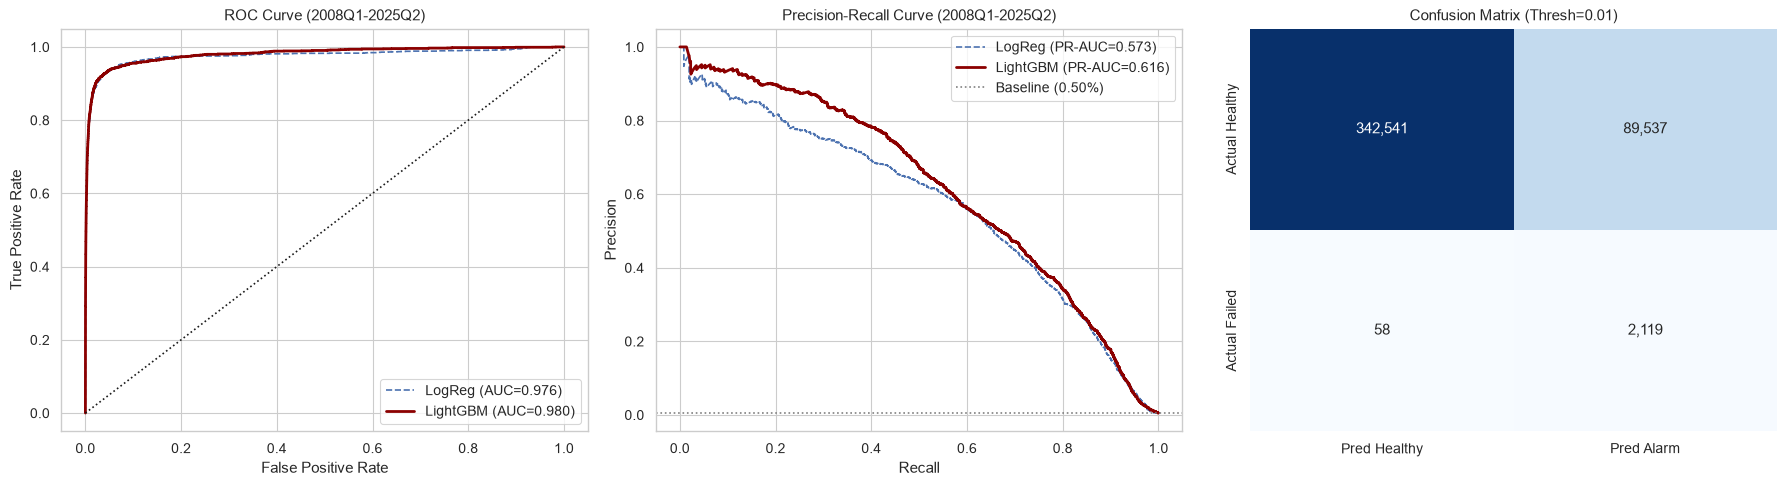


6. Production Serving Benchmark (Joblib Artifact: 719.5 KB):
   -> Single-Bank Interactive Latency : 33.70 ms/request (SLA < 50 ms: PASS)
   -> Quarterly Batch Scoring Latency : 0.0217 ms/bank (5,000 banks scored in 0.11s)

7. Distributed PySpark MLlib Demo (Reusing Shared SparkSession)...
   -> Spark MLlib GBT (Test 2008-2025): PR-AUC = 0.4837 | ROC-AUC = 0.9710 (Fit: 56.48s)
   -> Shared SparkSession stopped cleanly.

=== ALL PARTS COMPLETE (Total Part 5 Runtime: 500.5s) ===


In [6]:
print("=== PART 5: MODELLING, CACHED TUNING, OOF CALIBRATION & SPARK MLLIB ===")
t_p5 = time.time()

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    average_precision_score, roc_auc_score, confusion_matrix,
    precision_recall_curve, roc_curve, accuracy_score
)
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# -------------------------------------------------------------------------
# 1. Fast Interpretable Baseline: Logistic Regression Pipeline
# -------------------------------------------------------------------------
t0 = time.time()
lr_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("winsorizer", TrainOnlyWinsorizer((0.01, 0.99))),
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("cast32", Float32Caster())
        ]), num_cols),
        ("cat_nom", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(min_frequency=0.01, handle_unknown="ignore", sparse_output=False)),
            ("cast32", Float32Caster())
        ]), cat_nominal_cols)
    ],
    remainder="drop"
)

lr_baseline_pipeline = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("collinear", FastCollinearityDropper(0.85)),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=150, solver="lbfgs", random_state=RANDOM_SEED))
])
lr_baseline_pipeline.fit(X_dev, y_dev)
print(f"1. Logistic Regression Baseline fitted in {time.time() - t0:.2f}s")

# -------------------------------------------------------------------------
# 2. Main Model: LightGBM Atomic Pipeline with joblib.Memory Caching
# -------------------------------------------------------------------------
t0 = time.time()
sklearn_memory = Memory(location=str(CACHE_DIR), verbose=0)

lgb_full_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(tree_preprocessor)),
        ("var_thresh", VarianceThreshold(0.0)),
        ("collinear", FastCollinearityDropper(0.85)),
        ("filter", SelectPercentile(score_func=f_classif, percentile=80)),
        ("embedded", SelectFromModel(
            lgb.LGBMClassifier(n_estimators=50, learning_rate=0.08, class_weight="balanced", random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
            threshold="0.5*mean"
        )),
        ("classifier", lgb.LGBMClassifier(
            n_estimators=150, learning_rate=0.05, class_weight="balanced", random_state=RANDOM_SEED, n_jobs=-1, verbose=-1
        ))
    ],
    memory=sklearn_memory
)

param_grid = {
    "classifier__num_leaves": [15, 31]
}

grid_search = GridSearchCV(
    estimator=lgb_full_pipeline,
    param_grid=param_grid,
    cv=purged_cv,
    scoring="average_precision",
    n_jobs=1,
    refit=True
)
grid_search.fit(X_dev, y_dev)

best_lgb_pipeline = grid_search.best_estimator_
print(f"2. LightGBM Cached GridSearchCV fitted in {time.time() - t0:.2f}s")
print(f"   -> Best Params: {grid_search.best_params_} | Best Purged CV PR-AUC: {grid_search.best_score_:.4f}")

# -------------------------------------------------------------------------
# 3. Single-Pass OOF Predictions -> Used for BOTH Calibration & Regime Audit
# -------------------------------------------------------------------------
print("\n3. Generating Purged Out-of-Fold (OOF) Predictions (Single Pass)...")
oof_records = []
for fold_idx, (fold_name, tr_end, val_start, val_end) in enumerate(dev_fold_specs):
    tr_idx = np.where(df_dev["REPDTE"] <= pd.to_datetime(tr_end))[0]
    va_idx = np.where((df_dev["REPDTE"] >= pd.to_datetime(val_start)) & (df_dev["REPDTE"] <= pd.to_datetime(val_end)))[0]

    fold_pipe = clone(best_lgb_pipeline)
    fold_pipe.fit(X_dev.iloc[tr_idx], y_dev[tr_idx])
    va_probs = fold_pipe.predict_proba(X_dev.iloc[va_idx])[:, 1]

    oof_records.append(pd.DataFrame({
        "fold_name": fold_name,
        "REPDTE": df_dev["REPDTE"].iloc[va_idx].values,
        "y_true": y_dev[va_idx],
        "oof_prob": va_probs
    }))

oof_df = pd.concat(oof_records, ignore_index=True)
oof_df.to_parquet(MODEL_DIR / "oof_predictions.parquet", index=False)

# Regime Audit directly from stored OOF predictions (Zero redundant fits!)
regime_rows = []
for fname, grp in oof_df.groupby("fold_name", sort=False):
    prev = grp["y_true"].mean()
    pr = average_precision_score(grp["y_true"], grp["oof_prob"])
    roc = roc_auc_score(grp["y_true"], grp["oof_prob"])
    regime_rows.append({
        "Validation_Regime": fname,
        "Rows": len(grp),
        "Pos_Rate": f"{prev:.3%}",
        "OOF_PR_AUC": round(pr, 4),
        "Lift_vs_Random": f"{pr / max(prev, 1e-6):.1f}x",
        "OOF_ROC_AUC": round(roc, 4)
    })
print("\n=== REGIME GENERALIZATION AUDIT (REUSED OOF PREDICTIONS) ===")
print(pd.DataFrame(regime_rows).to_string(index=False))

# Cost-Sensitive Threshold Calibration on Development OOF (Localized to VN Context)
COST_FN = 800_000_000  # $800M USD (~20 trillion VND at 1 USD = 25,000 VND)
DEFAULT_COST_FP = 25_000  # $25,000 USD (~625M VND) baseline SBV on-site inspection cost

print(f"\n4. Cost-Sensitive Threshold Calibration (Development OOF - VN Supervisory Context):")
print(f"   -> Localized Missed-Failure Cost (COST_FN, VN restructuring benchmark): ${COST_FN:,.0f} (~20T VND)")
print(f"   -> SBV On-Site Audit Cost Proxy (COST_FP): $10,000 / $25,000 / $50,000 per flagged bank-quarter")

thresholds = np.linspace(0.01, 0.99, 199)
optimal_threshold = 0.50
oof_y_arr = oof_df["y_true"].values
oof_p_arr = oof_df["oof_prob"].values

for cost_fp in [10_000, 25_000, 50_000]:
    min_loss = float("inf")
    best_t = 0.50
    for t in thresholds:
        preds = (oof_p_arr >= t).astype(int)
        fp = np.sum((preds == 1) & (oof_y_arr == 0))
        fn = np.sum((preds == 0) & (oof_y_arr == 1))
        loss = fn * COST_FN + fp * cost_fp
        if loss < min_loss:
            min_loss = loss
            best_t = t
    print(f"   -> Proxy Audit Cost = ${cost_fp:,} | Ratio FN:FP = {COST_FN/cost_fp:,.0f}:1 | Optimal Threshold = {best_t:.3f}")
    if cost_fp == DEFAULT_COST_FP:
        optimal_threshold = best_t

# -------------------------------------------------------------------------
# 4. Single-Shot Evaluation on Unseen Holdout Test Set (2008Q1 - 2025Q2)
# -------------------------------------------------------------------------
print("\n5. Single-Shot Final Evaluation on Holdout Test Set (2008Q1 - 2025Q2)...")
lr_test_probs = lr_baseline_pipeline.predict_proba(X_test)[:, 1]
lgb_test_probs = best_lgb_pipeline.predict_proba(X_test)[:, 1]

def compute_eval_metrics(y_true, y_probs, thresh, cost_fp=DEFAULT_COST_FP, cost_fn=COST_FN):
    preds = (y_probs >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    far = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    return {
        "ROC_AUC": roc_auc_score(y_true, y_probs),
        "PR_AUC": average_precision_score(y_true, y_probs),
        "Accuracy": accuracy_score(y_true, preds),
        "Recall": recall,
        "Precision": precision,
        "FAR": far,
        "F1": f1,
        "Audit_Flags": int(tp + fp),
        "Missed_Quarters": int(fn),
        "Systemic_Loss_M": (fp * cost_fp + fn * cost_fn) / 1e6
    }

metrics_df = pd.DataFrame({
    "LogReg_Baseline (0.50)": compute_eval_metrics(y_test, lr_test_probs, 0.50),
    "LightGBM_Default (0.50)": compute_eval_metrics(y_test, lgb_test_probs, 0.50),
    f"LightGBM_Optimal ({optimal_threshold:.2f})": compute_eval_metrics(y_test, lgb_test_probs, optimal_threshold)
})
metrics_df.to_csv(RES_DIR / "model_metrics.csv")
print("\n=== FINAL OUT-OF-TIME TEST METRICS (SINGLE-SHOT) ===")
print(metrics_df.round(4).to_string())

# Save Academic Plots directly from stored test probabilities
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_test_probs)
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, lgb_test_probs)
axes[0].plot(fpr_lr, tpr_lr, "--", label=f"LogReg (AUC={metrics_df.loc['ROC_AUC', 'LogReg_Baseline (0.50)']:.3f})")
axes[0].plot(fpr_lgb, tpr_lgb, color="darkred", lw=2, label=f"LightGBM (AUC={metrics_df.loc['ROC_AUC', 'LightGBM_Default (0.50)']:.3f})")
axes[0].plot([0, 1], [0, 1], "k:")
axes[0].set_title("ROC Curve (2008Q1-2025Q2)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

prec_lr, rec_lr, _ = precision_recall_curve(y_test, lr_test_probs)
prec_lgb, rec_lgb, _ = precision_recall_curve(y_test, lgb_test_probs)
axes[1].plot(rec_lr, prec_lr, "--", label=f"LogReg (PR-AUC={metrics_df.loc['PR_AUC', 'LogReg_Baseline (0.50)']:.3f})")
axes[1].plot(rec_lgb, prec_lgb, color="darkred", lw=2, label=f"LightGBM (PR-AUC={metrics_df.loc['PR_AUC', 'LightGBM_Default (0.50)']:.3f})")
axes[1].axhline(y_test.mean(), color="gray", linestyle=":", label=f"Baseline ({y_test.mean():.2%})")
axes[1].set_title("Precision-Recall Curve (2008Q1-2025Q2)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right")

opt_cm = confusion_matrix(y_test, (lgb_test_probs >= optimal_threshold).astype(int))
sns.heatmap(opt_cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["Pred Healthy", "Pred Alarm"], yticklabels=["Actual Healthy", "Actual Failed"])
axes[2].set_title(f"Confusion Matrix (Thresh={optimal_threshold:.2f})")

plt.tight_layout()
plt.savefig(FIG_DIR / "test_evaluation_summary.png", dpi=200)
plt.show()

# -------------------------------------------------------------------------
# 5. Production Serialization (Joblib) & Honest Latency Check
# -------------------------------------------------------------------------
# Strip cache reference before dumping production artifact
best_lgb_pipeline.memory = None
artifact_path = MODEL_DIR / "fdic_ews_pipeline.joblib"
joblib.dump({
    "pipeline": best_lgb_pipeline,
    "optimal_threshold": optimal_threshold,
    "cost_fn_usd": COST_FN,
    "feature_schema": feature_cols
}, artifact_path)

loaded_pkg = joblib.load(artifact_path)
prod_pipe = loaded_pkg["pipeline"]

# Measure both single-row interactive latency and quarterly batch throughput
sample_1 = X_test.iloc[:1]
t0 = time.time()
for _ in range(200):
    _ = prod_pipe.predict_proba(sample_1)[:, 1]
single_latency_ms = ((time.time() - t0) / 200) * 1000

sample_batch = X_test.iloc[:5000]
t0 = time.time()
_ = prod_pipe.predict_proba(sample_batch)[:, 1]
batch_per_bank_ms = ((time.time() - t0) / 5000) * 1000

print(f"\n6. Production Serving Benchmark (Joblib Artifact: {os.path.getsize(artifact_path)/1024:.1f} KB):")
print(f"   -> Single-Bank Interactive Latency : {single_latency_ms:.2f} ms/request (SLA < 50 ms: {'PASS' if single_latency_ms < 50 else 'FAIL'})")
print(f"   -> Quarterly Batch Scoring Latency : {batch_per_bank_ms:.4f} ms/bank (5,000 banks scored in {batch_per_bank_ms*5:.2f}s)")

# -------------------------------------------------------------------------
# 6. Distributed PySpark MLlib Demo (Parquet-Backed, Zero Python-Worker Hang)
# -------------------------------------------------------------------------
print("\n7. Distributed PySpark MLlib Demo (Reusing Shared SparkSession)...")
sp_train_tmp = SPARK_LOCAL_DIR / "sp_mllib_train.parquet"
sp_test_tmp = SPARK_LOCAL_DIR / "sp_mllib_test.parquet"

try:
    fitted_feat_pipe = best_lgb_pipeline[:-1]
    rng = np.random.RandomState(RANDOM_SEED)
    fail_idx = np.where(y_dev == 1)[0]
    healthy_idx = rng.choice(np.where(y_dev == 0)[0], size=40_000, replace=False)
    sample_idx = rng.permutation(np.concatenate([fail_idx, healthy_idx]))

    X_tr_sp = fitted_feat_pipe.transform(X_dev.iloc[sample_idx])
    X_te_sp = fitted_feat_pipe.transform(X_test)
    sp_cols = [f"f_{i}" for i in range(X_tr_sp.shape[1])]

    df_sp_tr = pd.DataFrame(X_tr_sp, columns=sp_cols)
    df_sp_tr["LABEL_FAIL_1YR"] = y_dev[sample_idx].astype(np.int32)
    df_sp_te = pd.DataFrame(X_te_sp, columns=sp_cols)
    df_sp_te["LABEL_FAIL_1YR"] = y_test.astype(np.int32)

    # Write via PyArrow and read natively in Spark JVM (bypasses Python 3.13 createDataFrame bug)
    df_sp_tr.to_parquet(sp_train_tmp, index=False)
    df_sp_te.to_parquet(sp_test_tmp, index=False)
    del X_tr_sp, X_te_sp, df_sp_tr, df_sp_te
    gc.collect()

    assembler = VectorAssembler(inputCols=sp_cols, outputCol="features")
    sp_train_vec = assembler.transform(spark.read.parquet(str(sp_train_tmp.resolve()))).select("features", "LABEL_FAIL_1YR").cache()
    sp_test_vec = assembler.transform(spark.read.parquet(str(sp_test_tmp.resolve()))).select("features", "LABEL_FAIL_1YR")

    t0 = time.time()
    gbt = GBTClassifier(labelCol="LABEL_FAIL_1YR", featuresCol="features", maxIter=25, maxDepth=5, stepSize=0.05, seed=RANDOM_SEED)
    gbt_model = gbt.fit(sp_train_vec)
    sp_preds = gbt_model.transform(sp_test_vec)

    sp_pr = BinaryClassificationEvaluator(labelCol="LABEL_FAIL_1YR", metricName="areaUnderPR").evaluate(sp_preds)
    sp_roc = BinaryClassificationEvaluator(labelCol="LABEL_FAIL_1YR", metricName="areaUnderROC").evaluate(sp_preds)
    print(f"   -> Spark MLlib GBT (Test 2008-2025): PR-AUC = {sp_pr:.4f} | ROC-AUC = {sp_roc:.4f} (Fit: {time.time() - t0:.2f}s)")
finally:
    if spark is not None:
        spark.stop()
        print("   -> Shared SparkSession stopped cleanly.")
    for f_tmp in [sp_train_tmp, sp_test_tmp]:
        if f_tmp.exists():
            f_tmp.unlink()

print(f"\n=== ALL PARTS COMPLETE (Total Part 5 Runtime: {time.time() - t_p5:.1f}s) ===")